In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, 
    roc_auc_score, precision_recall_curve, auc
)

df = pd.read_excel('../excel/HR_Attrition_Analysis.xlsx', sheet_name='Data')

print("Shape of Data:", df.shape)
df.head()

Shape of Data: (1470, 36)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,...,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,AgeGroup,TenureGroup,AttritionFlag,IncomeBand
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,...,0,1,6,4,0,5,40-49,6-10,1,Q3 Mid-High
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,...,3,3,10,7,1,7,40-49,6-10,0,Q3 Mid-High
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,...,3,3,0,0,0,0,30-39,0-2,1,Q1 Low
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,...,3,3,8,7,3,0,30-39,6-10,0,Q1 Low
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,...,3,3,2,2,2,2,<30,0-2,0,Q2 Mid-Low


Attrition Distribution (%):
 Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


C:\Users\HP\AppData\Local\Temp\ipykernel_13448\919903083.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Attrition', palette='Set2')


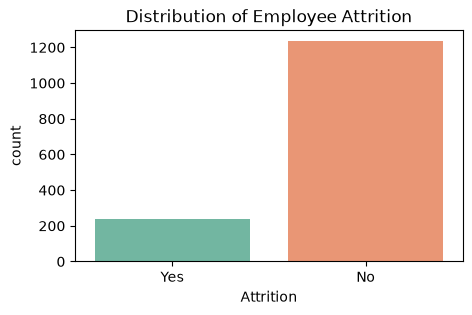

In [14]:

attrition_counts = df['Attrition'].value_counts(normalize=True) * 100
print("Attrition Distribution (%):\n", attrition_counts)


plt.figure(figsize=(5, 3))
sns.countplot(data=df, x='Attrition', palette='Set2')
plt.title('Distribution of Employee Attrition')
plt.show()

In [15]:

emp_numbers = df['EmployeeNumber']


X = df.drop(columns=[
    'Attrition', 'EmployeeCount', 'StandardHours', 'Over18', 
    'EmployeeNumber', 'AttritionFlag', 'AgeGroup', 'TenureGroup', 'IncomeBand'
], errors='ignore')

y = df['AttritionFlag']


num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()


preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
])

model = Pipeline(steps=[
    ('pre', preprocessor),
    ('lr', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

C:\Users\HP\AppData\Local\Temp\ipykernel_13448\1741653481.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()


In [16]:

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)


model.fit(X_tr, y_tr)

y_pred = model.predict(X_te)
y_prob = model.predict_proba(X_te)[:, 1]


print("Confusion Matrix:\n", confusion_matrix(y_te, y_pred))
print("\nClassification Report:\n", classification_report(y_te, y_pred))
print("ROC-AUC Score:", roc_auc_score(y_te, y_prob))

precision, recall, _ = precision_recall_curve(y_te, y_prob)
print("PR-AUC (Average Precision):", auc(recall, precision))

Confusion Matrix:
 [[191  56]
 [ 16  31]]

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.77      0.84       247
           1       0.36      0.66      0.46        47

    accuracy                           0.76       294
   macro avg       0.64      0.72      0.65       294
weighted avg       0.83      0.76      0.78       294

ROC-AUC Score: 0.8035145146007409
PR-AUC (Average Precision): 0.5675073264217703


In [17]:

cat_encoder = model.named_steps['pre'].named_transformers_['cat']
encoded_cat_cols = cat_encoder.get_feature_names_out(cat_cols).tolist()
all_features = num_cols + encoded_cat_cols

coefficients = model.named_steps['lr'].coef_[0]
odds_ratios = np.exp(coefficients)


importance_df = pd.DataFrame({
    'Feature': all_features,
    'Coefficient': coefficients,
    'OddsRatio': odds_ratios
}).sort_values(by='OddsRatio', ascending=False)

print("Top Factors Increasing Attrition Risk (Odds Ratios):")
print(importance_df.head(10))

Top Factors Increasing Attrition Risk (Odds Ratios):
                             Feature  Coefficient  OddsRatio
43                      OverTime_Yes     1.623568   5.071150
23  BusinessTravel_Travel_Frequently     1.598904   4.947606
34     JobRole_Laboratory Technician     1.569722   4.805314
40      JobRole_Sales Representative     1.276684   3.584733
24      BusinessTravel_Travel_Rarely     0.906933   2.476714
42              MaritalStatus_Single     0.864752   2.374416
33           JobRole_Human Resources     0.645775   1.907464
7                           JobLevel     0.547244   1.728483
21           YearsSinceLastPromotion     0.491743   1.635164
11                NumCompaniesWorked     0.459191   1.582793


In [18]:

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probabilities = cross_val_predict(model, X, y, cv=cv, method='predict_proba')[:, 1]


df['AttritionProbability'] = oof_probabilities

threshold_high = np.percentile(oof_probabilities, 90)
threshold_med = np.percentile(oof_probabilities, 70)

def assign_risk_level(prob):
    if prob >= threshold_high:
        return 'High'
    elif prob >= threshold_med:
        return 'Medium'
    else:
        return 'Low'

df['RiskLevel'] = df['AttritionProbability'].apply(assign_risk_level)

df.to_csv('../data/processed/hr_attrition_scored.csv', index=False)
